# RoadScan: controlled detection experiments

## 0. Purpose, scope, and evidence rules
This notebook implements Track A detector experiments E1-E4. The existing 03-yolo-training notebook is preserved. ResNet18 is the required image-level reference; YOLO adds localization. Image-level F1 is compared only with image-level F1, never directly with detection mAP.

We train on Japan/India/Czech; China is development validation, not an untouched test. US is an external evaluation previously examined for the classification baseline. Local Saudi images are REQUIRED for local claims and are test-only; none are attached yet. No universal-generalization or zero-overfitting guarantee is made.

Each stage states its purpose, method, outputs, and limitations. We retain failed experiments. Model selection uses development data only. We save checkpoints, split manifests, environment versions, and a reload-tested model package.

## 1. Environment and reproducibility
Install the pinned Ultralytics version used in the earlier experiment, record all package versions, and fail early if GPU is unavailable. Pinning limits accidental software changes; random seeds do not guarantee identical results across different hardware.

In [1]:
from pathlib import Path
import json, sys, platform
BASE = Path('/kaggle/working/roadscan_experiments')
BASE.mkdir(exist_ok=True)
roots = [p.parent.parent for p in Path('/kaggle/input').rglob('train/images') if (p.parent.parent/'train/labels').is_dir()]
print('Python:', sys.version)
print('Dataset roots:', [str(p) for p in roots])
for root in roots:
    print('ROOT:', root)
    for part in ['train','val','test_US','test','valid']:
        d=root/part/'images'
        if d.is_dir():
            files=sorted(p.name for p in d.iterdir() if p.is_file())
            print(part, len(files), 'examples:', files[:5])
print('Input top-level:', [str(p) for p in Path('/kaggle/input').iterdir()])


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Dataset roots: ['/kaggle/input/datasets/sarvii7/roadscan-yolo/RoadScan_yolo']
ROOT: /kaggle/input/datasets/sarvii7/roadscan-yolo/RoadScan_yolo
train 21041 examples: ['Czech_000000.jpg', 'Czech_000001.jpg', 'Czech_000002.jpg', 'Czech_000006.jpg', 'Czech_000007.jpg']
val 1977 examples: ['China_MotorBike_000000.jpg', 'China_MotorBike_000001.jpg', 'China_MotorBike_000002.jpg', 'China_MotorBike_000003.jpg', 'China_MotorBike_000004.jpg']
test_US 4805 examples: ['United_States_000000.jpg', 'United_States_000001.jpg', 'United_States_000002.jpg', 'United_States_000003.jpg', 'United_States_000004.jpg']
Input top-level: ['/kaggle/input/datasets']


## 2. Install and record the training environment

Purpose: use a fixed Ultralytics release rather than silently changing software between trials. PyTorch is already supplied by Kaggle. This cell installs Ultralytics and ImageHash (for a perceptual similarity screen), records versions, and creates an experiment directory. GPU availability is checked again immediately before training.

References: https://docs.ultralytics.com/modes/train/ and https://docs.ultralytics.com/models/yolo11/ . YOLO11 is a supported Track A candidate, not a claim that newer automatically means better.

In [2]:
import subprocess, sys, json, random, platform, time, shutil, hashlib, re, gc
from pathlib import Path
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics==8.4.177', 'ImageHash==4.3.2'])
import numpy as np, pandas as pd, torch, torchvision, ultralytics, yaml
from PIL import Image, ImageDraw
from ultralytics import YOLO
from IPython.display import display, Markdown
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
BASE = Path('/kaggle/working/roadscan_experiments'); BASE.mkdir(exist_ok=True)
ENV = dict(python=sys.version, torch=torch.__version__, torchvision=torchvision.__version__, ultralytics=ultralytics.__version__, seed=SEED, gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
(BASE/'environment.json').write_text(json.dumps(ENV, indent=2))
(BASE/'requirements-lock.txt').write_bytes(subprocess.check_output([sys.executable, '-m', 'pip', 'freeze']))
print(ENV)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 2.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
{'python': '3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]', 'torch': '2.11.0+cu128', 'torchvision': '0.26.0+cu128', 'ultralytics': '8.4.177', 'seed': 42, 'gpu': 'Tesla T4'}


## 3. Audit annotations and freeze leakage-aware splits

Purpose: correct-looking training curves are meaningless if labels are malformed or near-identical frames cross split boundaries. We validate image readability, normalized YOLO boxes, image/label pairing, class balance, and exact/perceptual duplicates. We NEVER edit the source dataset. Invalid records are logged, not silently repaired.

Protocol: Japan/India/Czech supply train, in-domain development, and in-domain test. Numeric filename blocks are a conservative PROXY for capture sequences, not verified trip IDs; a boundary guard removes nearby frame IDs. China remains out-of-country development data; US is held out from detector selection (but has historical baseline exposure). We cap training at 8,000 images and retain natural background prevalence rather than enforcing 15%. Split manifests are saved. The new protocol is NOT directly comparable with the historical 600-image run.

A pHash screen removes training images within Hamming distance 4 of development/test images, and removes test images close to development. This reduces, but cannot prove absence of, semantic leakage. Empty label files are valid backgrounds, not proof of a perfectly healthy road. Output: audit CSV, invalid-record log, immutable split lists, class counts, YAMLs, and visual label examples.

Source: /kaggle/input/datasets/sarvii7/roadscan-yolo/RoadScan_yolo | valid: 27823 | excluded invalid: 0


images  boxes
source_split country                       
test_US      United_States      4805  11014
train        Czech              2829   1745
             India              7706   6831
             Japan             10506  16469
val          China_MotorBike    1977   4650

train 7984 backgrounds 3485 image class support {'D00': 1685, 'D10': 929, 'D20': 2468, 'D40': 1173}
in_domain_dev 1000 backgrounds 358 image class support {'D00': 250, 'D10': 153, 'D20': 349, 'D40': 126}
china_dev 1977 backgrounds 43 image class support {'D00': 1419, 'D10': 738, 'D20': 486, 'D40': 164}
in_domain_test 998 backgrounds 456 image class support {'D00': 220, 'D10': 109, 'D20': 269, 'D40': 171}
us_external 4805 backgrounds 0 image class support {'D00': 3907, 'D10': 2342, 'D20': 739, 'D40': 116}
development 1000 backgrounds 199 image class support {'D00': 473, 'D10': 255, 'D20': 283, 'D40': 102}
Cross-split exclusions: 18
Train manifest SHA256: 30e9b5fe39868c7007f27dc6516d509a7be50323f3f2b4d79723ee26e77144fa


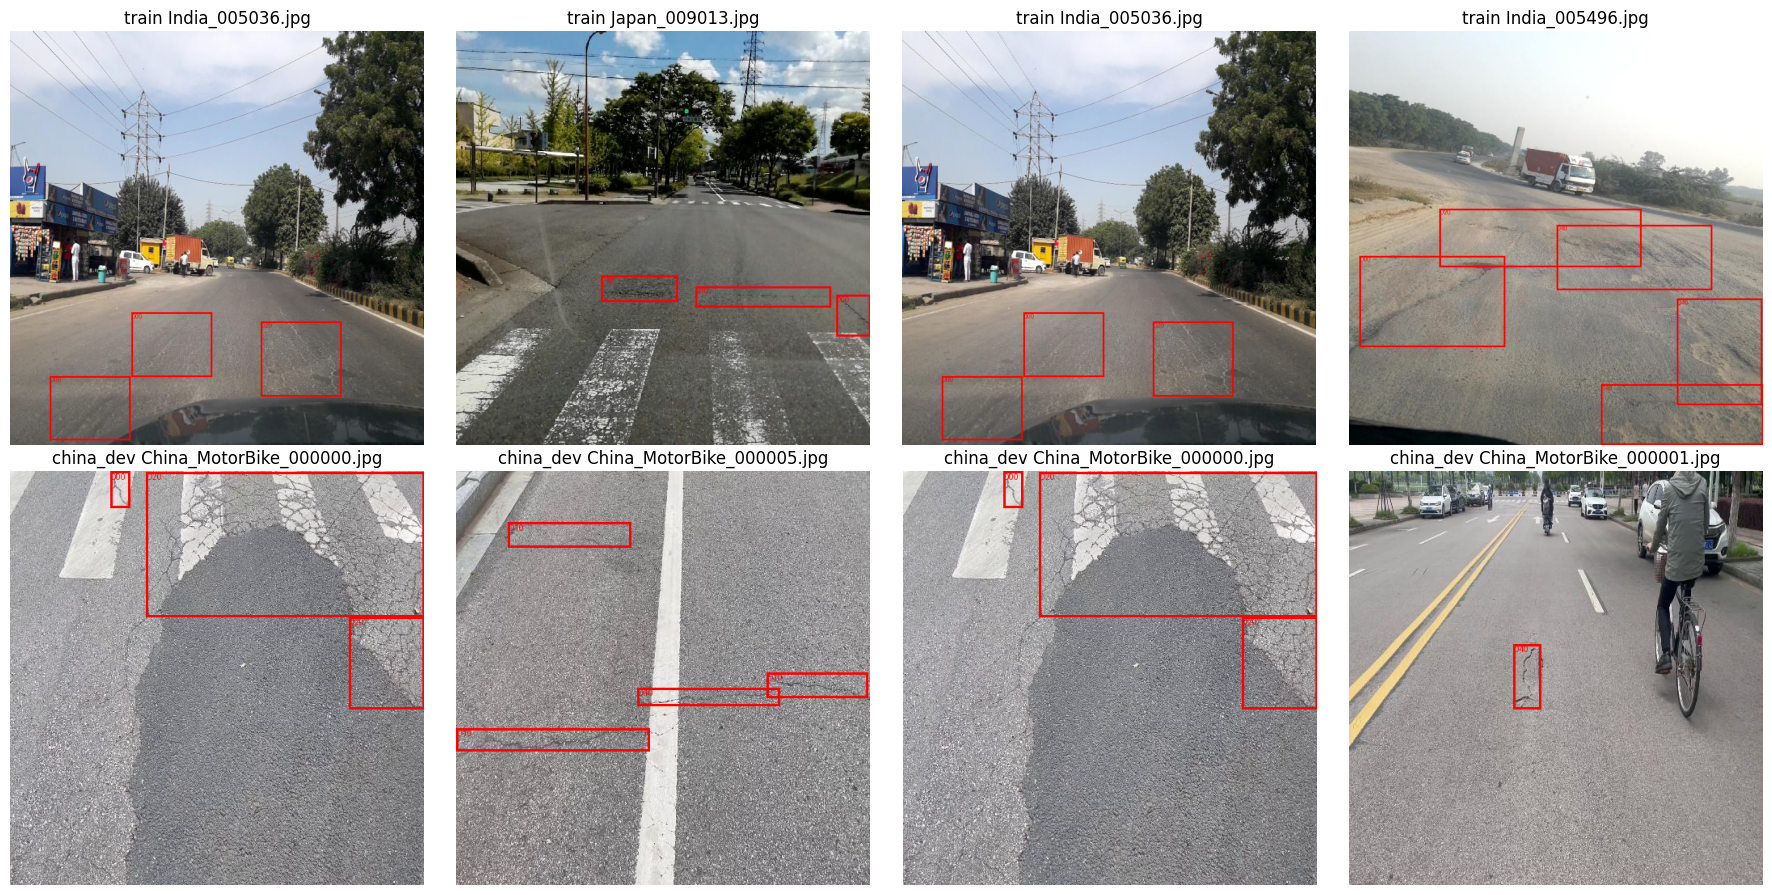

In [3]:
from concurrent.futures import ThreadPoolExecutor
from collections import Counter
import imagehash
roots = [p.parent.parent for p in Path('/kaggle/input').rglob('train/images') if (p.parent.parent/'train/labels').is_dir()]
assert len(roots)==1, f'Expected one dataset root, found {roots}'
SRC=roots[0]
CLASSES=['D00','D10','D20','D40']
rows=[]; invalid=[]
def inspect_image(item):
    split,p=item
    lab=p.parent.parent/'labels'/(p.stem+'.txt')
    try:
        if not lab.is_file(): raise ValueError('missing label')
        with Image.open(p) as im:
            w,h=im.size; im.verify()
        boxes=[]
        for line in lab.read_text().splitlines():
            if not line.strip(): continue
            v=list(map(float,line.split()))
            if len(v)!=5 or not np.isfinite(v).all(): raise ValueError('invalid numeric row')
            c,x,y,bw,bh=v
            if c!=int(c) or not 0<=c<4: raise ValueError('invalid class')
            if not (0<=x<=1 and 0<=y<=1 and 0<bw<=1 and 0<bh<=1): raise ValueError('invalid normalized box')
            if min(x-bw/2,y-bh/2)<-0.002 or max(x+bw/2,y+bh/2)>1.002: raise ValueError('box extends outside image')
            boxes.append(v)
        country=p.stem.rsplit('_',1)[0]
        frame_id=int(p.stem.rsplit('_',1)[1])
        y=[int(any(int(v[0])==c for v in boxes)) for c in range(4)]
        return dict(path=str(p), label=str(lab), country=country, frame=frame_id, source_split=split, width=w,height=h,boxes=len(boxes), **{CLASSES[c]:y[c] for c in range(4)}),None
    except Exception as e: return None,dict(path=str(p),error=str(e))
items=[(s,p) for s in ['train','val','test_US'] for p in sorted((SRC/s/'images').glob('*.jpg'))]
assert items, 'No JPG images found in expected folders.'
with ThreadPoolExecutor(max_workers=8) as pool:
    for good,bad in pool.map(inspect_image,items):
        if good: rows.append(good)
        if bad: invalid.append(bad)
df=pd.DataFrame(rows); df.to_csv(BASE/'data_audit.csv',index=False)
pd.DataFrame(invalid,columns=['path','error']).to_csv(BASE/'invalid_records.csv',index=False)
print('Source:', SRC, '| valid:',len(df),'| excluded invalid:',len(invalid))
display(df.groupby(['source_split','country']).agg(images=('path','size'),boxes=('boxes','sum')))
assert len(df)>8000, 'Dataset too small or substantially changed; review before training.'
df['block']=df['frame']//200
df['bucket']=[int(hashlib.sha256(f'{c}:{b}:42'.encode()).hexdigest()[:8],16)%10 for c,b in zip(df.country,df.block)]
source=df[df.source_split=='train'].copy()
assert set(source.country.unique())=={'Japan','India','Czech'}, f'Unexpected training countries: {source.country.unique()}'
source=source[(source.frame%200>=10)&(source.frame%200<190)]
train=source[source.bucket>=4].sample(frac=1,random_state=42).head(8000)
in_dev=source[source.bucket<2].sample(frac=1,random_state=42).head(1000)
in_test=source[(source.bucket>=2)&(source.bucket<4)].sample(frac=1,random_state=42).head(1000)
china=df[df.source_split=='val'].copy()
us=df[df.source_split=='test_US'].copy()
# pHash/byte hash screen, using no model predictions or test metrics.
def fingerprints(p):
    with Image.open(p) as im: ph=int(str(imagehash.phash(im.convert('RGB'))),16)
    return p,(hashlib.sha256(Path(p).read_bytes()).hexdigest(),ph)
paths=sorted(set(pd.concat([train,in_dev,in_test,china,us]).path))
with ThreadPoolExecutor(max_workers=8) as pool: fps=dict(pool.map(fingerprints,paths))
class BKTree:
    def __init__(self): self.root=None
    def add(self,v):
        if self.root is None: self.root=[v,{}]; return
        n=self.root
        while True:
            d=(v^n[0]).bit_count()
            if d==0: return
            if d not in n[1]: n[1][d]=[v,{}]; return
            n=n[1][d]
    def near(self,v,t=4):
        stack=[self.root] if self.root else []
        while stack:
            a,ch=stack.pop(); d=(v^a).bit_count()
            if d<=t:return True
            stack.extend(node for k,node in ch.items() if d-t<=k<=d+t)
        return False
seen_sha=set(); tree=BKTree(); removed=[]
def clean_split(frame,name,check=True):
    keep=[]
    for r in frame.itertuples():
        sha,ph=fps[r.path]
        if check and (sha in seen_sha or tree.near(ph)):
            removed.append(dict(path=r.path,split=name,reason='cross-split exact/phash<=4'));continue
        keep.append(r.path)
    result=frame[frame.path.isin(keep)].copy()
    for p in result.path:
        sha,ph=fps[p]; seen_sha.add(sha);tree.add(ph)
    return result
# Keep China intact; subsequent splits are screened against previously reserved data.
china=clean_split(china,'china_dev',False)
in_dev=clean_split(in_dev,'in_domain_dev')
in_test=clean_split(in_test,'in_domain_test')
us=clean_split(us,'us_external')
train=clean_split(train,'train')
splits=dict(train=train,in_domain_dev=in_dev,china_dev=china,in_domain_test=in_test,us_external=us)
# Balanced-country development subset keeps per-epoch validation affordable.
dev=pd.concat([in_dev.sample(n=min(500,len(in_dev)),random_state=42),china.sample(n=min(500,len(china)),random_state=42)])
splits['development']=dev
for name,data in splits.items():
    data.to_csv(BASE/(name+'_manifest.csv'),index=False)
    (BASE/(name+'.txt')).write_text(chr(10).join(data.path))
    print(name,len(data),'backgrounds',int((data.boxes==0).sum()),'image class support',data[CLASSES].sum().to_dict())
pd.DataFrame(removed,columns=['path','split','reason']).to_csv(BASE/'similarity_exclusions.csv',index=False)
assert len(train)>=4000 and len(in_test)>=100 and len(china)>=100, 'Split too small after screening; review exclusions.'
assert (train[CLASSES].sum()>20).all(), 'Insufficient class support.'
def write_yaml(name,val_name):
    cfg=dict(path=str(SRC),train=str(BASE/'train.txt'),val=str(BASE/(val_name+'.txt')),names=dict(enumerate(CLASSES)))
    p=BASE/(name+'.yaml');p.write_text(yaml.safe_dump(cfg));return str(p)
DATA=write_yaml('development','development')
YAMLS={name:write_yaml('eval_'+name,name) for name in ['in_domain_dev','china_dev','in_domain_test','us_external']}
print('Cross-split exclusions:',len(removed))
print('Train manifest SHA256:',hashlib.sha256((BASE/'train_manifest.csv').read_bytes()).hexdigest())
# Visual QA: one positive example of each class from both train and China.
import matplotlib.pyplot as plt
fig,axes=plt.subplots(2,4,figsize=(18,9))
for row,(name,data) in enumerate([('train',train),('china_dev',china)]):
    for c in range(4):
        r=data[data[CLASSES[c]]==1].iloc[0]
        im=Image.open(r.path).convert('RGB');draw=ImageDraw.Draw(im);w,h=im.size
        for line in Path(r.label).read_text().splitlines():
            if not line.strip():continue
            cl,x,y,bw,bh=map(float,line.split());box=[(x-bw/2)*w,(y-bh/2)*h,(x+bw/2)*w,(y+bh/2)*h]
            draw.rectangle(box,outline='red',width=3);draw.text((box[0],box[1]),CLASSES[int(cl)],fill='red')
        axes[row,c].imshow(im);axes[row,c].set_title(name+' '+Path(r.path).name);axes[row,c].axis('off')
fig.tight_layout();fig.savefig(BASE/'annotation_qa.jpg',dpi=160);plt.show()


## 4. E1 reference: ResNet18 multilabel classifier

Purpose: rebuild an image-level reference on EXACTLY the new training manifest, so the detector comparison is meaningful. This is a newly trained reference, not the historical teammate weights. ResNet18 sees full images resized to 384; YOLO sees letterboxed images at 640. E1 compares complete pipelines, not architecture alone.

Method: three epochs train the head with the backbone frozen (including BN statistics), then seven fine-tune at a smaller learning rate. Select by development BCE, and tune image-level thresholds on development only. Save weights, preprocessing, loss curves, and per-class metrics. Threshold-tuned development F1 is optimistic and is not final evidence; external tests are evaluated only after selection. An always-positive reference is also reported later.

This baseline is intentionally simple, not deliberately sabotaged. Its purpose is to quantify whether localization adds practical value.

In [4]:
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import f1_score, precision_recall_fscore_support, roc_auc_score
import copy
assert torch.cuda.is_available(), 'GPU required for the bounded training stage.'
DEVICE='cuda:0'
torch.set_num_threads(2)
TF=transforms.Compose([transforms.Resize((384,384)),transforms.ToTensor(),transforms.Normalize([.485,.456,.406],[.229,.224,.225])])
class RoadImages(Dataset):
    def __init__(self,records): self.records=records.reset_index(drop=True)
    def __len__(self): return len(self.records)
    def __getitem__(self,i):
        r=self.records.iloc[i]
        with Image.open(r.path) as im: x=TF(im.convert('RGB'))
        return x,torch.tensor(r[CLASSES].to_numpy(dtype=np.float32))
def loader(data,shuffle=False): return DataLoader(RoadImages(data),batch_size=32,shuffle=shuffle,num_workers=2,pin_memory=True)
tr_dl=loader(train,True);dev_dl=loader(dev)
torch.manual_seed(SEED)
resnet=models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
resnet.fc=nn.Linear(resnet.fc.in_features,4);resnet=resnet.to(DEVICE)
for p in resnet.parameters():p.requires_grad=False
for p in resnet.fc.parameters():p.requires_grad=True
optimizer=torch.optim.Adam(resnet.fc.parameters(),lr=1e-3)
criterion=nn.BCEWithLogitsLoss()
history=[];best_loss=float('inf');best_state=None
for epoch in range(1,11):
    if epoch==4:
        for p in resnet.parameters():p.requires_grad=True
        optimizer=torch.optim.Adam(resnet.parameters(),lr=1e-4)
    # Keep backbone batch-normalization frozen while training only the head.
    resnet.train(epoch>=4);resnet.fc.train()
    total=0.;count=0
    for x,y in tr_dl:
        x,y=x.to(DEVICE),y.to(DEVICE);optimizer.zero_grad(set_to_none=True)
        loss=criterion(resnet(x),y);loss.backward();optimizer.step()
        total+=loss.item()*len(x);count+=len(x)
    resnet.eval();va=0.;vn=0
    with torch.inference_mode():
        for x,y in dev_dl:
            x,y=x.to(DEVICE),y.to(DEVICE);va+=criterion(resnet(x),y).item()*len(x);vn+=len(x)
    va/=vn;history.append(dict(epoch=epoch,train_loss=total/count,val_loss=va))
    if va<best_loss:
        best_loss=va;best_state=copy.deepcopy({k:v.cpu() for k,v in resnet.state_dict().items()})
    print(history[-1],flush=True)
    pd.DataFrame(history).to_csv(BASE/'resnet_history.csv',index=False)
resnet.load_state_dict(best_state);torch.save(best_state,BASE/'baseline_resnet18.pt')
@torch.inference_mode()
def resnet_probs(data):
    resnet.eval();out=[]
    for x,_ in loader(data):out.append(torch.sigmoid(resnet(x.to(DEVICE))).cpu().numpy())
    return np.concatenate(out)
def tune_thresholds(y,p):
    grid=np.arange(.05,.96,.05)
    return [float(max(grid,key=lambda t:f1_score(y[:,i],p[:,i]>=t,zero_division=0))) for i in range(4)]
def image_report(y,p,thresholds):
    pred=p>=np.asarray(thresholds)
    pr,rc,f1,support=precision_recall_fscore_support(y,pred,zero_division=0)
    return pd.DataFrame(dict(class_name=CLASSES,precision=pr,recall=rc,f1=f1,support=support,threshold=thresholds))
y_dev=dev[CLASSES].to_numpy(dtype=int)
baseline_probs=resnet_probs(dev);baseline_th=tune_thresholds(y_dev,baseline_probs)
baseline_report=image_report(y_dev,baseline_probs,baseline_th)
baseline_report.to_csv(BASE/'resnet_development_metrics.csv',index=False)
np.save(BASE/'resnet_development_probabilities.npy',baseline_probs)
(BASE/'baseline_config.json').write_text(json.dumps(dict(thresholds=baseline_th,classes=CLASSES,img_size=384,seed=SEED,mean=[.485,.456,.406],std=[.229,.224,.225]),indent=2))
display(baseline_report)
print('Development macro-F1 (optimistic selection metric):',baseline_report.f1.mean())
resnet=resnet.cpu();torch.cuda.empty_cache()


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 174MB/s]


{'epoch': 1, 'train_loss': 0.44601769855839457, 'val_loss': 0.5890738000869751}
{'epoch': 2, 'train_loss': 0.41177368229759004, 'val_loss': 0.6114957437515259}
{'epoch': 3, 'train_loss': 0.40154627831522116, 'val_loss': 0.587993556022644}
{'epoch': 4, 'train_loss': 0.3585241585074064, 'val_loss': 0.5993751678466797}
{'epoch': 5, 'train_loss': 0.24756840385033754, 'val_loss': 0.5034921655654907}
{'epoch': 6, 'train_loss': 0.14098922750037277, 'val_loss': 0.7114799284934997}
{'epoch': 7, 'train_loss': 0.05993708912917751, 'val_loss': 0.7987110724449158}
{'epoch': 8, 'train_loss': 0.0301232716565082, 'val_loss': 0.786507734298706}
{'epoch': 9, 'train_loss': 0.013848243200990982, 'val_loss': 0.7425223159790039}
{'epoch': 10, 'train_loss': 0.009667014566908976, 'val_loss': 0.8293072571754455}


,class_name,precision,recall,f1,support,threshold
0,D00,0.586777,0.900634,0.710592,473,0.1
1,D10,0.525424,0.729412,0.610837,255,0.2
2,D20,0.853175,0.759717,0.803738,283,0.4
3,D40,0.190972,0.539216,0.282051,102,0.5


Development macro-F1 (optimistic selection metric): 0.6018047995913453


## 5. E2-E3: controlled detector training and selection

Purpose: measure the quality/compute trade-off of YOLO11 nano vs small (E2), then isolate Mosaic and color-policy effects (E3). Each starts from COCO weights, NOT another trial. Standard vs no-Mosaic changes only Mosaic; standard vs mild-color changes only color policy. Vertical flips and unrealistic perspective changes are disabled.

All trials share audited data, seed, image size, batch and optimizer. The initial epoch setting is 60 and early-stopping patience is 12. The active 45-minute time budget takes precedence over the epoch setting: Ultralytics can adapt the planned epoch count. Actual completed epochs and elapsed time are reported, NOT assumed equal. Four trials have approximately three hours of training budget plus preparation, validation and packaging. A time-capped small model may be under-trained. Failed trials are retained. Selection uses mixed DEVELOPMENT mAP50-95 only.

Outputs: best/last and periodic checkpoints, loss/PR/F1 curves, per-trial results.csv, experiments.csv, failure logs, and ZIP snapshots. Working files are not proof of durable persistence: verify the completed Save & Run All Output. The highest score does not establish production readiness. CPU benchmarks fix two threads after predictor initialization and record the actual count.

In [5]:
# Predeclared plan: shared split, seed and optimizer; equal time budgets, not guaranteed equal epochs.
TRIALS=[
 dict(name='E2_nano_standard',weights='yolo11n.pt',mosaic=1.0,hsv_s=.7,hsv_v=.4),
 dict(name='E2_small_standard',weights='yolo11s.pt',mosaic=1.0,hsv_s=.7,hsv_v=.4),
 dict(name='E3_nano_no_mosaic',weights='yolo11n.pt',mosaic=0.0,hsv_s=.7,hsv_v=.4),
 dict(name='E3_nano_mild_color',weights='yolo11n.pt',mosaic=1.0,hsv_s=.3,hsv_v=.2),
]
(BASE/'experiment_plan.json').write_text(json.dumps(TRIALS,indent=2))
COMMON=dict(data=DATA,epochs=60,patience=12,imgsz=640,batch=16,device=0,workers=2,seed=42,deterministic=True,optimizer='AdamW',lr0=.001,weight_decay=.0005,cos_lr=True,warmup_epochs=3,close_mosaic=10,fliplr=.5,flipud=0.,degrees=0.,perspective=0.,mixup=0.,cache=False,save=True,save_period=10,plots=True,project=str(BASE/'runs'),time=.75)
# time=.75 takes precedence over the initial epochs setting; report actual epochs and elapsed time.
(BASE/'common_training_config.json').write_text(json.dumps(COMMON,indent=2))
records=[];failures=[]
def package_snapshot():
    return shutil.make_archive('/kaggle/working/roadscan_results','zip',root_dir=BASE)
for spec in TRIALS:
    started=time.time()
    try:
        detector=YOLO(spec['weights'])
        detector.train(**COMMON,name=spec['name'],mosaic=spec['mosaic'],hsv_s=spec['hsv_s'],hsv_v=spec['hsv_v'])
        run=Path(detector.trainer.save_dir)
        best=run/'weights/best.pt'
        assert best.is_file(), 'Missing best checkpoint'
        detector=YOLO(str(best))
        metrics=detector.val(data=DATA,imgsz=640,batch=16,device=0,workers=2,plots=True,project=str(BASE/'validation'),name=spec['name'])
        hist=pd.read_csv(run/'results.csv');hist.columns=hist.columns.str.strip()
        rec=dict(name=spec['name'],weights=spec['weights'],checkpoint=str(best),map50=float(metrics.box.map50),map50_95=float(metrics.box.map),precision=float(metrics.box.mp),recall=float(metrics.box.mr),epochs_completed=int(hist.epoch.max()),seconds=round(time.time()-started,2),mosaic=spec['mosaic'],hsv_s=spec['hsv_s'],hsv_v=spec['hsv_v'])
        records.append(rec)
        pd.DataFrame(records).to_csv(BASE/'experiments.csv',index=False)
        display(pd.DataFrame(records))
        display(Markdown('**Observed result:** '+spec['name']+' completed '+str(rec['epochs_completed'])+' epochs. Development mAP50-95 = '+str(round(rec['map50_95'],4))+'. Compare actual epochs before interpreting size/augmentation differences; wall-time ceilings can yield unequal optimization.'))
        del detector;gc.collect();torch.cuda.empty_cache()
    except Exception as e:
        failures.append(dict(name=spec['name'],error=repr(e)))
        (BASE/'failed_trials.json').write_text(json.dumps(failures,indent=2))
        print('TRIAL FAILED:',spec['name'],repr(e),flush=True)
        gc.collect();torch.cuda.empty_cache()
    finally:
        package_snapshot()
assert records, 'All trials failed; inspect failed_trials.json.'
experiments=pd.DataFrame(records).sort_values('map50_95',ascending=False)
WINNER=experiments.iloc[0].checkpoint
(BASE/'selection.json').write_text(json.dumps(dict(checkpoint=WINNER,criterion='highest mixed-development mAP50-95; tests not used',experiments=records),indent=2))
print('Selected on development ONLY:',WINNER)
display(experiments)


New https://pypi.org/project/ultralytics/8.4.178 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/roadscan_experiments/development.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, m

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/26      2.26G      2.216      3.054      2.044         29        640: 100% ━━━━━━━━━━━━ 499/499 6.9it/s 1:12
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 5.5it/s 5.8s
                   all       1000       1743       0.11      0.194     0.0656     0.0198

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/30      2.26G      2.176      2.928      2.007         30        640: 100% ━━━━━━━━━━━━ 499/499 7.0it/s 1:11
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 5.0it/s 6.5s
                   all       1000       1743      0.164      0.131     0.0738     0.0217

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/32      2.26G      2.118      2.871      1.964         27        640: 100% ━━━━━━━━━━━━ 499/499 7.1it/s 1:11
                 Class     Images  Instances      Box(P 

,name,weights,checkpoint,map50,map50_95,precision,recall,epochs_completed,seconds,mosaic,hsv_s,hsv_v
0,E2_nano_standard,yolo11n.pt,/kaggle/working/roadscan_experiments/runs/E2_n...,0.303942,0.134977,0.353734,0.355506,36,2808.44,1.0,0.7,0.4


**Observed result:** E2_nano_standard completed 36 epochs. Development mAP50-95 = 0.135. Compare actual epochs before interpreting size/augmentation differences; wall-time ceilings can yield unequal optimization.

New https://pypi.org/project/ultralytics/8.4.178 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/roadscan_experiments/development.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, m

... (6 outputs left out)

,name,weights,checkpoint,map50,map50_95,precision,recall,epochs_completed,seconds,mosaic,hsv_s,hsv_v
0,E2_nano_standard,yolo11n.pt,/kaggle/working/roadscan_experiments/runs/E2_n...,0.303942,0.134977,0.353734,0.355506,36,2808.44,1.0,0.7,0.4
1,E2_small_standard,yolo11s.pt,/kaggle/working/roadscan_experiments/runs/E2_s...,0.289239,0.121193,0.390011,0.326394,26,2796.49,1.0,0.7,0.4
2,E3_nano_no_mosaic,yolo11n.pt,/kaggle/working/roadscan_experiments/runs/E3_n...,0.249530,0.113885,0.378232,0.284023,38,2776.21,0.0,0.7,0.4
3,E3_nano_mild_color,yolo11n.pt,/kaggle/working/roadscan_experiments/runs/E3_n...,0.293716,0.125812,0.374793,0.321734,35,2770.83,1.0,0.3,0.2


**Observed result:** E3_nano_mild_color completed 35 epochs. Development mAP50-95 = 0.1258. Compare actual epochs before interpreting size/augmentation differences; wall-time ceilings can yield unequal optimization.

Selected on development ONLY: /kaggle/working/roadscan_experiments/runs/E2_nano_standard/weights/best.pt


,name,weights,checkpoint,map50,map50_95,precision,recall,epochs_completed,seconds,mosaic,hsv_s,hsv_v
0,E2_nano_standard,yolo11n.pt,/kaggle/working/roadscan_experiments/runs/E2_n...,0.303942,0.134977,0.353734,0.355506,36,2808.44,1.0,0.7,0.4
3,E3_nano_mild_color,yolo11n.pt,/kaggle/working/roadscan_experiments/runs/E3_n...,0.293716,0.125812,0.374793,0.321734,35,2770.83,1.0,0.3,0.2
1,E2_small_standard,yolo11s.pt,/kaggle/working/roadscan_experiments/runs/E2_s...,0.289239,0.121193,0.390011,0.326394,26,2796.49,1.0,0.7,0.4
2,E3_nano_no_mosaic,yolo11n.pt,/kaggle/working/roadscan_experiments/runs/E3_n...,0.249530,0.113885,0.378232,0.284023,38,2776.21,0.0,0.7,0.4


## 6. E1 and E4: fair comparisons, operating point, and generalization

Purpose: separate classification performance from localization performance and quantify domain shift. Choose the detector confidence using development F1 curves, documenting that this optimizes F1 rather than a validated municipal cost function. Image-level probabilities are the maximum box confidence per class; their own thresholds are fitted on development, separately from the detection operating point.

Compare ResNet18, YOLO and an always-positive image-level reference on identical examples with frozen thresholds. Report detection mAP50, mAP50-95, AP per class, precision/recall and saved PR/F1/confusion plots. China results are DEVELOPMENT evidence, not independent generalization. In-domain test and US results are examined only after model selection and are not fed back into tuning during this run. US has historical baseline exposure.

CPU latency is measured after warm-up with fixed threads and image size. Nano-vs-small training results alone do not establish a CPU speed trade-off; the selected detector latency is measured here, and both E2 models are benchmarked in the next stage. Local Saudi evaluation remains pending until 40-80 independently annotated images are supplied. Do not infer local performance from US or China scores.

In [6]:
detector=YOLO(WINNER)
# Derive a confidence operating point from development F1 curves, never from tests.
cal=detector.val(data=DATA,imgsz=640,batch=16,device=0,workers=2,plots=True,project=str(BASE/'validation'),name='selected_calibration')
CONF=None
for title,curve in zip(cal.curves,cal.curves_results):
    if 'F1' in title:
        xs=np.asarray(curve[0]);ys=np.asarray(curve[1]);avg=ys.mean(axis=0) if ys.ndim==2 else ys
        CONF=float(xs[int(np.argmax(avg))]);break
assert CONF is not None, 'F1 confidence curve unavailable; inspect installed metrics API.'
print('Development-selected detection confidence:',CONF)
(BASE/'operating_point.json').write_text(json.dumps(dict(confidence=CONF,criterion='maximum mean per-class detection F1 on development; not a safety certification',iou_eval=.5),indent=2))
def detector_probs(data):
    lookup={p:i for i,p in enumerate(data.path)};out=np.zeros((len(data),4),np.float32)
    for r in detector.predict(source=data.path.tolist(),imgsz=640,conf=.001,device=0,batch=16,stream=True,verbose=False):
        i=lookup[str(Path(r.path))]
        if len(r.boxes):
            for c,s in zip(r.boxes.cls.cpu().numpy().astype(int),r.boxes.conf.cpu().numpy()):out[i,c]=max(out[i,c],float(s))
    return out
yp=detector_probs(dev);det_th=tune_thresholds(y_dev,yp)
(BASE/'detector_image_thresholds.json').write_text(json.dumps(det_th))
image_rows=[];det_rows=[]
resnet=resnet.to(DEVICE)
for split_name in ['in_domain_dev','china_dev','in_domain_test','us_external']:
    data=splits[split_name];y=data[CLASSES].to_numpy(dtype=int)
    m=detector.val(data=YAMLS[split_name],imgsz=640,batch=16,device=0,workers=2,plots=True,project=str(BASE/'evaluation'),name=split_name)
    row=dict(split=split_name,images=len(data),mAP50=float(m.box.map50),mAP50_95=float(m.box.map),precision=float(m.box.mp),recall=float(m.box.mr))
    det_rows.append(row)
    class_rows=[]
    for j,c in enumerate(m.box.ap_class_index):
        pp,rr,ap50,ap=m.box.class_result(j)
        class_rows.append(dict(class_name=CLASSES[int(c)],precision=float(pp),recall=float(rr),AP50=float(ap50),AP50_95=float(ap)))
    pd.DataFrame(class_rows).to_csv(BASE/(split_name+'_detection_by_class.csv'),index=False)
    # Shared image-level E1 evaluation, with thresholds frozen on development.
    rp=resnet_probs(data);dp=detector_probs(data)
    for method,probs,ths in [('ResNet18',rp,baseline_th),('YOLO11',dp,det_th),('AlwaysPositive',np.ones_like(rp),[.5]*4)]:
        report=image_report(y,probs,ths);report.to_csv(BASE/(split_name+'_'+method+'_image_metrics.csv'),index=False)
        image_rows.append(dict(split=split_name,model=method,macro_F1=float(report.f1.mean()),micro_F1=float(f1_score(y,probs>=np.asarray(ths),average='micro',zero_division=0))))
    pd.DataFrame(det_rows).to_csv(BASE/'E4_detection.csv',index=False)
    pd.DataFrame(image_rows).to_csv(BASE/'E1_image_comparison.csv',index=False)
    display(pd.DataFrame(det_rows));display(pd.DataFrame(image_rows))
    package_snapshot()
resnet=resnet.cpu();torch.cuda.empty_cache()
# CPU latency on development images only; warm-up excluded, end-to-end predict included.
torch.set_num_threads(2)
bench=YOLO(WINNER);paths=dev.path.head(25).tolist();times=[]
for i,p in enumerate(paths):
    start=time.perf_counter();bench.predict(p,imgsz=640,conf=CONF,device='cpu',verbose=False)
    if i==0:torch.set_num_threads(2)
    if i>=5:times.append((time.perf_counter()-start)*1000)
CPU=dict(device=platform.processor(),threads=torch.get_num_threads(),images=len(times),image_size=640,median_ms=float(np.median(times)),p95_ms=float(np.percentile(times,95)),scope='Kaggle CPU end-to-end single-image predict, after 5 warmups; deployment hardware may differ')
(BASE/'cpu_benchmark.json').write_text(json.dumps(CPU,indent=2));print(CPU)


Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.7 ms, read: 75.8±58.2 MB/s, size: 66.5 KB)
val: Scanning /kaggle/input/datasets/sarvii7/roadscan-yolo/RoadScan_yolo/train/labels... 1000 images, 199 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 866.8it/s 1.2s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/sarvii7/roadscan-yolo/RoadScan_yolo/train is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 63/63 6.6it/s 9.5s
                   all       1000       1743      0.354      0.356      0.304      0.135
                   D00        473        830      0.346      0.242       0.21     0.0815
                   D10        255        389      0.268      0.261      0.212     0.0733
                   D20        283        374      0.49

OutOfMemoryError: CUDA out of memory. Tried to allocate 3.05 GiB. GPU 0 has a total capacity of 14.56 GiB of which 2.99 GiB is free. Including non-PyTorch memory, this process has 11.57 GiB memory in use. Of the allocated memory 10.82 GiB is allocated by PyTorch, and 614.30 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

## 7. Error analysis, CPU trade-off, and verified model bundle

Purpose: explain failure modes instead of reporting only a global score. On 100 fixed DEVELOPMENT images, match ground-truth/predicted boxes one-to-one at IoU 0.5 and categorize missed damage, wrong class, localization errors, and false-positive/duplicate predictions. Categories are diagnostic heuristics, not human-verified root causes. Show ground truth and predictions side by side.

Measure nano and small CPU latency on identical development inputs and inspect a training-data probe versus independent development/test scores. A gap is evidence to investigate, not automatic proof of overfitting or its absence.

Package best.pt, class mapping, image size, confidence, pinned dependencies and a command-line inference script. Launch a FRESH Python process to reload weights and predict before declaring the bundle usable. Produce checksums, a report with actual scores and limitations, and roadscan_results.zip. Save & Run All must finish and the saved Output files must be verified before stopping/releasing GPU. Local evaluation and E5 remain explicitly incomplete until their required data/work are available.

In [ ]:
# E2 CPU comparison: identical inputs, image size, threads, warm-ups and timing scope.
cpu_rows=[]
for r in records:
    if r['name'] not in ['E2_nano_standard','E2_small_standard']:continue
    bm=YOLO(r['checkpoint']);elapsed=[]
    for i,p in enumerate(dev.path.head(25)):
        t=time.perf_counter();bm.predict(p,imgsz=640,conf=CONF,device='cpu',verbose=False)
        if i==0:torch.set_num_threads(2)
        if i>=5:elapsed.append((time.perf_counter()-t)*1000)
    cpu_rows.append(dict(trial=r['name'],median_ms=float(np.median(elapsed)),p95_ms=float(np.percentile(elapsed,95)),threads=torch.get_num_threads(),images=len(elapsed)))
pd.DataFrame(cpu_rows).to_csv(BASE/'E2_cpu_comparison.csv',index=False);display(pd.DataFrame(cpu_rows))
# Diagnostic train-vs-validation probe. Never used to select another model after tests.
probe=train.sample(n=min(1000,len(train)),random_state=42)
(BASE/'train_probe.txt').write_text(chr(10).join(probe.path))
probe_cfg=yaml.safe_load(Path(DATA).read_text());probe_cfg['val']=str(BASE/'train_probe.txt')
(BASE/'train_probe.yaml').write_text(yaml.safe_dump(probe_cfg))
pm=detector.val(data=str(BASE/'train_probe.yaml'),imgsz=640,device=0,batch=16,workers=2,plots=False,project=str(BASE/'evaluation'),name='training_diagnostic')
(BASE/'training_diagnostic.json').write_text(json.dumps(dict(images=len(probe),map50=float(pm.box.map50),map50_95=float(pm.box.map),warning='Training-set diagnostic is not independent accuracy. Gaps can reflect both overfitting and domain shift.'),indent=2))
# One-to-one IoU matching for explicit error categories on fixed development examples.
from torchvision.ops import box_iou
error_rows=[]
examples=dev.sample(n=min(100,len(dev)),random_state=42)
fig,axes=plt.subplots(4,2,figsize=(14,20))
for idx,r in enumerate(examples.itertuples()):
    im=Image.open(r.path).convert('RGB');w,h=im.size;gt=[];gcids=[]
    for line in Path(r.label).read_text().splitlines():
        if not line.strip():continue
        c,x,y,bw,bh=map(float,line.split());gcids.append(int(c));gt.append([(x-bw/2)*w,(y-bh/2)*h,(x+bw/2)*w,(y+bh/2)*h])
    pred=detector.predict(r.path,imgsz=640,conf=CONF,device=0,verbose=False)[0]
    pb=pred.boxes.xyxy.cpu();pc=pred.boxes.cls.cpu().numpy().astype(int)
    ious=box_iou(torch.tensor(gt,dtype=torch.float32).reshape(-1,4),pb).numpy()
    pairs=sorted([(float(ious[g,p]),g,p) for g in range(len(gt)) for p in range(len(pc)) if gcids[g]==pc[p] and ious[g,p]>=.5],reverse=True)
    usedg=set();usedp=set()
    for _,g,p in pairs:
        if g not in usedg and p not in usedp:usedg.add(g);usedp.add(p)
    for g,c in enumerate(gcids):
        if g in usedg:continue
        overlap=ious[g].max() if len(pc) else 0.
        kind='wrong_class' if any(ious[g,p]>=.5 and pc[p]!=c for p in range(len(pc))) else ('localization' if overlap>=.1 else 'missed_damage')
        error_rows.append(dict(image=Path(r.path).name,class_name=CLASSES[c],error=kind,best_iou=float(overlap)))
    for p,c in enumerate(pc):
        if p not in usedp:error_rows.append(dict(image=Path(r.path).name,class_name=CLASSES[c],error='false_positive_or_duplicate',best_iou=float(ious[:,p].max()) if len(gt) else 0.))
    if idx<4:
        draw=ImageDraw.Draw(im)
        for box,c in zip(gt,gcids):draw.rectangle(box,outline='red',width=3);draw.text((box[0],box[1]),CLASSES[c],fill='red')
        axes[idx,0].imshow(im);axes[idx,0].set_title('Ground truth '+Path(r.path).name);axes[idx,0].axis('off')
        axes[idx,1].imshow(pred.plot()[...,::-1]);axes[idx,1].set_title('Predictions at development confidence');axes[idx,1].axis('off')
errors=pd.DataFrame(error_rows,columns=['image','class_name','error','best_iou']);errors.to_csv(BASE/'error_examples.csv',index=False)
if len(errors):display(errors.groupby(['class_name','error']).size().unstack(fill_value=0))
fig.tight_layout();fig.savefig(BASE/'ground_truth_vs_predictions.jpg',dpi=140);plt.show()
# Portable model package and a genuinely fresh Python-process reload test.
bundle=BASE/'model_bundle';bundle.mkdir(exist_ok=True)
shutil.copy2(WINNER,bundle/'best.pt')
config=dict(classes=CLASSES,imgsz=640,confidence=CONF,source_weights=WINNER,ultralytics=ultralytics.__version__,local_validation='PENDING - no local Saudi test attached',intended_use='Research prototype; human review required')
(bundle/'config.json').write_text(json.dumps(config,indent=2))
infer_lines=[
 'from pathlib import Path', 'import argparse, json', 'from ultralytics import YOLO',
 'p=argparse.ArgumentParser();p.add_argument("--image",required=True);args=p.parse_args()',
 'root=Path(__file__).resolve().parent', 'cfg=json.loads((root/"config.json").read_text())',
 'model=YOLO(str(root/"best.pt"))',
 'results=model.predict(args.image,imgsz=cfg["imgsz"],conf=cfg["confidence"],device="cpu",save=True,project=str(root/"predictions"),verbose=False)',
 'print("Fresh-process prediction succeeded",len(results))'
]
(bundle/'predict.py').write_text(chr(10).join(infer_lines))
(bundle/'requirements.txt').write_text('ultralytics=='+ultralytics.__version__+chr(10))
reload=subprocess.run([sys.executable,str(bundle/'predict.py'),'--image',dev.path.iloc[0]],capture_output=True,text=True,timeout=180)
(BASE/'fresh_process_reload.txt').write_text(reload.stdout+reload.stderr)
assert reload.returncode==0, 'Fresh-process reload failed; inspect reload log.'
print(reload.stdout)
report=['# RoadScan experiment report', '', '## Selection', experiments.to_markdown(index=False), '', '## E1 image-level comparison',pd.DataFrame(image_rows).to_markdown(index=False),'','## E4 detection evaluation',pd.DataFrame(det_rows).to_markdown(index=False),'','## E2 CPU latency',pd.DataFrame(cpu_rows).to_markdown(index=False),'','## Interpretation and limitations','The highest mixed-development mAP50-95 selected the checkpoint, not any test result. Read actual epochs alongside the 45-minute cap. Per-class results and error categories are saved separately. No claim of zero overfitting, universal performance, or local Saudi success is supported. Filename blocks are sequence proxies, not trip IDs. pHash screens can miss near-duplicates or remove distinct similar roads.','Local test: PENDING. E5 retrieval, priority sensitivity and integrated application are outside this detector notebook. US has historical reference-model exposure; reserve a new independent local test for stronger evidence.','Image-level E1 compares pipelines at different input resolutions and cannot isolate architecture alone. Confidence maximizes development F1 and needs operational cost validation.','## Reuse','Run: python model_bundle/predict.py --image /path/to/road.jpg','Model weights and configuration were reloaded and tested in a fresh Python process.','## Required next evidence','40-80 safely captured local test images with YOLO labels; keep locations/trips disjoint and blur faces/plates. Never tune on this test set.']
(BASE/'REPORT.md').write_text(chr(10).join(report))
(bundle/'MODEL_CARD.md').write_text(chr(10).join(report[-12:]))
checks={str(p.relative_to(BASE)):hashlib.sha256(p.read_bytes()).hexdigest() for p in BASE.rglob('*') if p.is_file() and p.name!='SHA256.json'}
(BASE/'SHA256.json').write_text(json.dumps(checks,indent=2))
archive=package_snapshot();print('FINAL PACKAGE:',archive)
display(Markdown((BASE/'REPORT.md').read_text()))
